In [6]:
from pymeasure.instruments.keithley import Keithley2400
from pymeasure.adapters import SerialAdapter
import serial.tools.list_ports
from typing import List, Dict, Tuple
import asyncio
import logging
import numpy as np
import pandas as pd
from time import sleep
import time


In [7]:
adapter = '/dev/ttyUSB1'
adapter = SerialAdapter(adapter, baudrate=9600, timeout=2, parity='N', stopbits=1, rtscts=False)
adapter.write_termination = "\n"
sourcemeter = Keithley2400(adapter)

In [8]:
# Set the input parameters
data_points = 3 # Maybe set this higher
averages = 10
max_current = 0.001
min_current = -max_current


In [9]:

# Set source_current and measure_voltage parameters
current_range = 10e-3  # in Amps
compliance_voltage = 0.5  # in Volts
measure_nplc = 0.1  # Number of power line cycles
voltage_range = 0.001  # in VOlts


In [10]:
# Connect and configure the instrument
sourcemeter.reset()
sourcemeter.use_front_terminals()
sourcemeter.apply_current(current_range, compliance_voltage)

In [11]:
sourcemeter.measure_voltage(measure_nplc, voltage_range)
sleep(0.1)  # wait here to give the instrument time to react
sourcemeter.stop_buffer()
sourcemeter.disable_buffer()

In [12]:

# Allocate arrays to store the measurement results
currents = np.linspace(min_current, max_current, num=data_points)
voltages = np.zeros_like(currents)
voltage_stds = np.zeros_like(currents)


In [13]:

sourcemeter.enable_source()


In [14]:

# Loop through each current point, measure and record the voltage
for i in range(data_points):
    print(f"Reading for datapoint {i}") 
    sourcemeter.config_buffer(averages)
    sourcemeter.source_current = currents[i]
    sourcemeter.start_buffer()
    sourcemeter.wait_for_buffer()
    # Record the average and standard deviation
    voltages[i] = sourcemeter.means[0]
    sleep(1.0)
    voltage_stds[i] = sourcemeter.standard_devs[0]


Reading for datapoint 0
Reading for datapoint 1
Reading for datapoint 2


In [15]:

# Save the data columns in a CSV file
data = pd.DataFrame({
    'Current (A)': currents,
    'Voltage (V)': voltages,
    'Voltage Std (V)': voltage_stds,
})

In [16]:
sourcemeter.shutdown()

In [17]:
data

,Current (A),Voltage (V),Voltage Std (V)
0,-0.001,-0.152469,0.000003
1,0.000,0.000045,0.000004
2,0.001,0.152461,0.000005


In [18]:
def get_iv_curve(sourcemeter, start_voltage, stop_voltage, step_voltage, compliance_current, source_voltage_range):
    """
    Performs an IV curve measurement using a Keithley 2400 sourcemeter.

    Args:
        sourcemeter (Keithley2400): The Keithley 2400 instrument object.
        start_voltage (float): The starting voltage (V).
        stop_voltage (float): The stopping voltage (V).
        step_voltage (float): The voltage step size (V).
        compliance_current (float): The current compliance limit (A).
        source_voltage_range (float): The source voltage range (V).

    Returns:
        tuple: A tuple containing the voltage and current arrays.
    """
    try:
        sourcemeter.reset()
        sourcemeter.use_front_terminals()  # Or sourcemeter.use_rear_terminals()
        sourcemeter.apply_voltage()
        sourcemeter.source_voltage_range = source_voltage_range
        sourcemeter.compliance_current = compliance_current
        sourcemeter.measure_current()
        sourcemeter.enable_source()

        voltages = np.arange(start_voltage, stop_voltage + step_voltage, step_voltage)
        currents = []

        for voltage in voltages:
            print("Curr voltage", voltage)
            sourcemeter.source_voltage = voltage
            time.sleep(0.05)  # Add a small delay for settling
            current = sourcemeter.current
            currents.append(current)

        sourcemeter.disable_source()

        return voltages, currents

    except Exception as e:
        print(f"An error occurred: {e}")
        return None, None  # Return None for both if an error occurs.
    finally:
        try:
            sourcemeter.disable_source()
        except:
            pass

In [19]:
start_voltage = -0.005  # Sets the starting voltage for the IV curve sweep to -1 millivolt (mV). This is the initial voltage applied to the device under test (DUT).
stop_voltage = 0.005   # Sets the ending voltage for the IV curve sweep to 1 millivolt (mV). This is the final voltage applied to the DUT.
step_voltage = 0.001  # Sets the voltage increment between each measurement point to 0.1 millivolt (mV). This determines the resolution of the IV curve. Smaller step sizes result in more data points and a more detailed curve.
compliance_current = 0.1 # Sets the maximum allowed current to 0.1 Amperes (A). This is a safety measure to prevent damage to the DUT. If the current exceeds this limit, the sourcemeter will stop applying voltage.
source_voltage_range = 20 # Max allowed voltage, must be higher than start/stop

voltages, currents = get_iv_curve(sourcemeter, start_voltage, stop_voltage, step_voltage, compliance_current, source_voltage_range)

Curr voltage -0.005
Curr voltage -0.004
Curr voltage -0.003
Curr voltage -0.002
Curr voltage -0.001
Curr voltage 0.0
Curr voltage 0.001
Curr voltage 0.002
Curr voltage 0.003
Curr voltage 0.004000000000000001
Curr voltage 0.005


In [20]:
import matplotlib.pyplot as plt
def plot_iv_curve(voltages, currents):
    """
    Plots the IV curve.

    Args:
        voltages (list or numpy.ndarray): The voltage values.
        currents (list or numpy.ndarray): The current values.
    """
    if voltages is not None and currents is not None:
        plt.plot(voltages, currents)
        plt.xlabel('Voltage (V)')
        plt.ylabel('Current (A)')
        plt.title('IV Curve')
        plt.grid(True)
        plt.show()


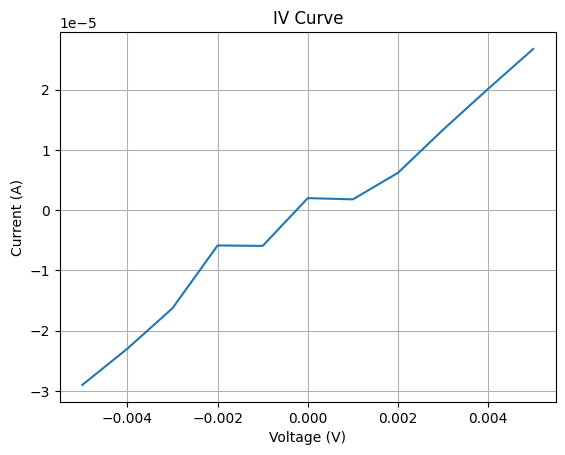

In [21]:
plot_iv_curve(voltages, currents)

In [22]:
voltages, currents

(array([-0.005, -0.004, -0.003, -0.002, -0.001,  0.   ,  0.001,  0.002,
         0.003,  0.004,  0.005]),
 [-2.897673e-05,
  -2.295825e-05,
  -1.625295e-05,
  -5.848533e-06,
  -5.924215e-06,
  2.001332e-06,
  1.795693e-06,
  6.193326e-06,
  1.333994e-05,
  2.012273e-05,
  2.67405e-05])